In [ ]:
# ============================================================
# 1. IMPORTS Y CONFIGURACIÓN
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
)

# Configuración
tf.random.set_seed(42)
np.random.seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {keras.__version__}")

TensorFlow: 2.21.0
Keras: 3.15.1


In [ ]:
# ============================================================
# 2. CARGA DE DATOS
# ============================================================
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_sub = pd.read_csv("sample_submission.csv")

print(f"Train: {train.shape}")
print(f"Test: {test.shape}")

train.head()

Train: (8693, 14)
Test: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [ ]:
# ============================================================
# 3. ANÁLISIS EXPLORATORIO BÁSICO
# ============================================================
print("=== INFO ===")
train.info()

print("\n=== VALORES FALTANTES ===")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\n=== TARGET ===")
print(train["Transported"].value_counts())
print(f"Balance: {train['Transported'].mean():.4f}")

=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB

=== VALORES FALTANTES ===
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP  

In [ ]:
# ============================================================
# 4. FEATURE ENGINEERING SIMPLE
# ============================================================
def feature_engineering(df, is_train=True):
    df = df.copy()

    # PassengerId -> GroupId, MemberNum
    df["GroupId"] = df["PassengerId"].str.split("_").str[0]
    df["MemberNum"] = df["PassengerId"].str.split("_").str[1].astype(int)

    if is_train:
        df["GroupSize"] = df.groupby("GroupId")["PassengerId"].transform("count")

    # Cabin -> Deck, CabinNum, Side
    cabin_split = df["Cabin"].str.split("/", expand=True)
    if cabin_split.shape[1] == 3:
        df["Deck"] = cabin_split[0]
        df["CabinNum"] = pd.to_numeric(cabin_split[1], errors="coerce")
        df["Side"] = cabin_split[2]
    else:
        df["Deck"] = np.nan
        df["CabinNum"] = np.nan
        df["Side"] = np.nan

    # Gastos
    spending_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
    for col in spending_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["TotalSpending"] = df[spending_cols].sum(axis=1)
    df["HasSpending"] = (df["TotalSpending"] > 0).astype(int)

    # Booleanas a int
    for col in ["CryoSleep", "VIP"]:
        if col in df.columns:
            df[col] = df[col].map({True: 1, False: 0, "True": 1, "False": 0})

    if is_train and "Transported" in df.columns:
        df["Transported"] = df["Transported"].map(
            {True: 1, False: 0, "True": 1, "False": 0}
        )

    return df


train_fe = feature_engineering(train, is_train=True)
test_fe = feature_engineering(test, is_train=False)

# GroupSize para test
group_sizes = train_fe.groupby("GroupId")["GroupSize"].first()
test_fe["GroupSize"] = test_fe["GroupId"].map(group_sizes).fillna(1).astype(int)

print(f"Train FE: {train_fe.shape}")
print(f"Test FE: {test_fe.shape}")

Train FE: (8693, 22)
Test FE: (4277, 21)


In [ ]:
# ============================================================
# 5. IMPUTACIÓN SIMPLE
# ============================================================
def simple_imputation(train_df, test_df):
    train = train_df.copy()
    test = test_df.copy()

    spending_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

    # Gastos faltantes -> 0
    for col in spending_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)

    train["TotalSpending"] = train[spending_cols].sum(axis=1)
    test["TotalSpending"] = test[spending_cols].sum(axis=1)
    train["HasSpending"] = (train["TotalSpending"] > 0).astype(int)
    test["HasSpending"] = (test["TotalSpending"] > 0).astype(int)

    # CryoSleep: si gasto=0 -> 1, else 0
    cryo_mask_train = train["CryoSleep"].isna()
    cryo_mask_test = test["CryoSleep"].isna()
    train.loc[cryo_mask_train, "CryoSleep"] = (
        train.loc[cryo_mask_train, "TotalSpending"] == 0
    ).astype(int)
    test.loc[cryo_mask_test, "CryoSleep"] = (
        test.loc[cryo_mask_test, "TotalSpending"] == 0
    ).astype(int)

    # Moda para el resto
    for col in ["CryoSleep", "VIP", "HomePlanet", "Destination", "Deck", "Side"]:
        if train[col].isna().any():
            mode_val = train[col].mode()[0]
            train[col] = train[col].fillna(mode_val)
            test[col] = test[col].fillna(mode_val)

    # CabinNum -> mediana
    cabin_median = train["CabinNum"].median()
    train["CabinNum"] = train["CabinNum"].fillna(cabin_median)
    test["CabinNum"] = test["CabinNum"].fillna(cabin_median)

    # Age -> mediana
    age_median = train["Age"].median()
    train["Age"] = train["Age"].fillna(age_median)
    test["Age"] = test["Age"].fillna(age_median)

    print("Valores faltantes train:")
    print(train.isnull().sum()[train.isnull().sum() > 0])
    print("\nValores faltantes test:")
    print(test.isnull().sum()[test.isnull().sum() > 0])

    return train, test


train_imp, test_imp = simple_imputation(train_fe, test_fe)

Valores faltantes train:
Cabin    199
Name     200
dtype: int64

Valores faltantes test:
Cabin    100
Name      94
dtype: int64


In [ ]:
# ============================================================
# 6. PREPROCESAMIENTO CON SKLEARN
# ============================================================
# Separar features y target
drop_cols = ["PassengerId", "Name", "Cabin", "GroupId", "Transported"]
X = train_imp.drop(columns=[c for c in drop_cols if c in train_imp.columns])
y = train_imp["Transported"]
X_test = test_imp.drop(columns=[c for c in drop_cols if c in test_imp.columns])

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Categóricas: {cat_cols}")
print(f"Numéricas: {num_cols}")

# One-Hot Encoding para categóricas
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoder.fit(X[cat_cols])

X_cat = encoder.transform(X[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

cat_feature_names = []
for i, col in enumerate(cat_cols):
    for cat in encoder.categories_[i]:
        cat_feature_names.append(f"{col}_{cat}")

X_cat_df = pd.DataFrame(X_cat, columns=cat_feature_names, index=X.index)
X_test_cat_df = pd.DataFrame(X_test_cat, columns=cat_feature_names, index=X_test.index)

# Combinar
X_final = pd.concat(
    [X[num_cols].reset_index(drop=True), X_cat_df.reset_index(drop=True)], axis=1
)
X_test_final = pd.concat(
    [X_test[num_cols].reset_index(drop=True), X_test_cat_df.reset_index(drop=True)],
    axis=1,
)

# Escalado
scaler = StandardScaler()
X_final[num_cols] = scaler.fit_transform(X_final[num_cols])
X_test_final[num_cols] = scaler.transform(X_test_final[num_cols])

print(f"X_final shape: {X_final.shape}")
print(f"X_test_final shape: {X_test_final.shape}")

Categóricas: ['HomePlanet', 'Destination', 'Deck', 'Side']
Numéricas: ['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'MemberNum', 'GroupSize', 'CabinNum', 'TotalSpending', 'HasSpending']
X_final shape: (8693, 29)
X_test_final shape: (4277, 29)


In [7]:
# ============================================================
# 7. TRAIN/VALIDATION SPLIT
# ============================================================
X_train, X_val, y_train, y_val = train_test_split(
    X_final, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}")
print(f"Train target dist: {y_train.mean():.4f}")
print(f"Val target dist: {y_val.mean():.4f}")

Train: (6954, 29), Val: (1739, 29)
Train target dist: 0.5036
Val target dist: 0.5037


In [ ]:
# ============================================================
# 8. MODELO TENSORFLOW SIMPLE
# ============================================================
model = keras.Sequential(
    [
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ]
)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,161 (47.50 KB)

 Trainable params: 12,161 (47.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# 9. ENTRENAMIENTO
# ============================================================
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=15, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_auc", mode="max", factor=0.5, patience=7, min_lr=1e-6
    ),
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=256,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7015 - auc: 0.7634 - loss: 0.5861 - val_accuracy: 0.7619 - val_auc: 0.8474 - val_loss: 0.4990 - learning_rate: 0.0010
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7751 - auc: 0.8458 - loss: 0.4854 - val_accuracy: 0.7775 - val_auc: 0.8746 - val_loss: 0.4460 - learning_rate: 0.0010
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7811 - auc: 0.8647 - loss: 0.4569 - val_accuracy: 0.7867 - val_auc: 0.8832 - val_loss: 0.4245 - learning_rate: 0.0010
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7821 - auc: 0.8704 - loss: 0.4466 - val_accuracy: 0.7907 - val_auc: 0.8869 - val_loss: 0.4162 - learning_rate: 0.0010
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7922 - auc: 0.8752 - loss: 0.4368 - val_accuracy: 0.7913 - val_auc: 0.8902 - val_loss: 0.4091 - learning_rate: 0.0010
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8023 - auc: 0.8823 -

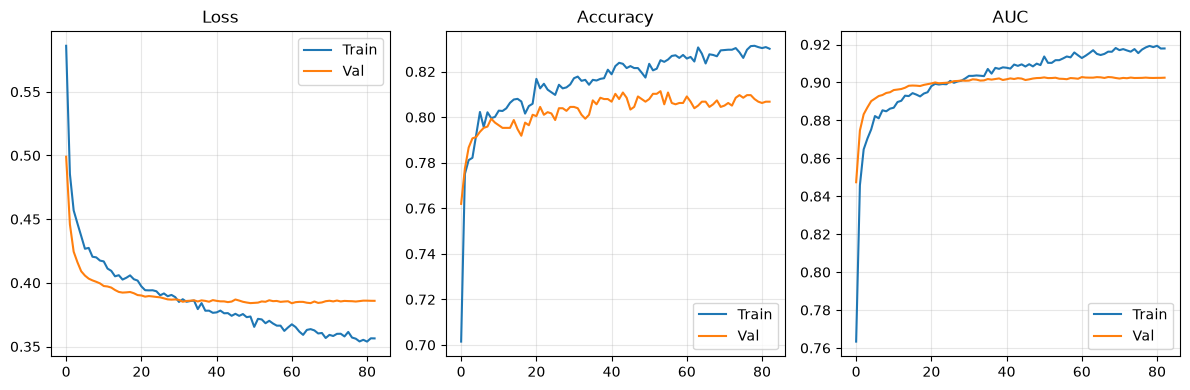

Validation Accuracy: 0.8056
Validation F1: 0.8014
Validation AUC: 0.9029

Classification Report:
                 precision    recall  f1-score   support

Not Transported       0.79      0.83      0.81       863
    Transported       0.83      0.78      0.80       876

       accuracy                           0.81      1739
      macro avg       0.81      0.81      0.81      1739
   weighted avg       0.81      0.81      0.81      1739



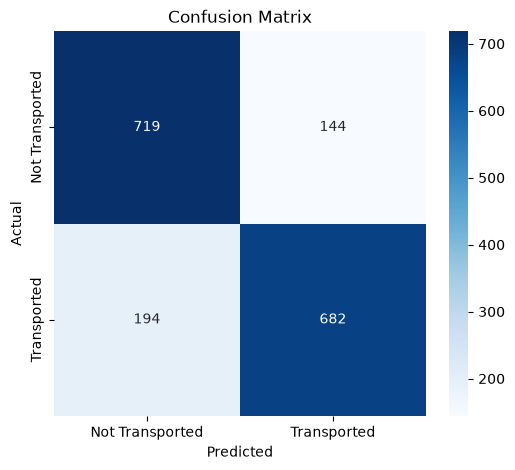

In [ ]:
# ============================================================
# 10. EVALUACIÓN
# ============================================================
# Curvas
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, (metric, title) in enumerate(
    [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]
):
    axes[i].plot(history.history[metric], label="Train")
    axes[i].plot(history.history[f"val_{metric}"], label="Val")
    axes[i].set_title(title)
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Métricas en validation
val_preds = model.predict(X_val, verbose=0).flatten()
val_preds_binary = (val_preds > 0.5).astype(int)

print(f"Validation Accuracy: {accuracy_score(y_val, val_preds_binary):.4f}")
print(f"Validation F1: {f1_score(y_val, val_preds_binary):.4f}")
print(f"Validation AUC: {roc_auc_score(y_val, val_preds):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val, val_preds_binary, target_names=["Not Transported", "Transported"]
    )
)

# Matriz de confusión

cm = confusion_matrix(y_val, val_preds_binary)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Transported", "Transported"],
    yticklabels=["Not Transported", "Transported"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# ============================================================
# 11. SUBMISSION
# ============================================================
test_preds = model.predict(X_test_final, verbose=0).flatten()
test_preds_binary = (test_preds > 0.5).astype(bool)

submission = pd.DataFrame(
    {"PassengerId": test_imp["PassengerId"], "Transported": test_preds_binary}
)

print(f"Submission shape: {submission.shape}")
print(f"Transported True: {submission['Transported'].sum()}")
print(f"Transported False: {(~submission['Transported']).sum()}")
print(f"Rate: {submission['Transported'].mean():.4f}")

submission.to_csv("submission.csv", index=False)
print("\nSubmission guardado en submission.csv")

submission.head(10)

Submission shape: (4277, 2)
Transported True: 2189
Transported False: 2088
Rate: 0.5118

Submission guardado en submission.csv


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
5,0027_01,True
6,0029_01,True
7,0032_01,True
8,0032_02,True
9,0033_01,False
